# Analisis Numerik — Regresi Revenue dan Titik Impas (*Breakeven Point*) pada 5 Gerai Donat

## **Nama:** Andina Maulidiasaputri  
## **NIM:** 25083010003

# Langkah Awal - Import Library, Load Data, dan Info Data

## Import Library

In [116]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from numpy.polynomial import Polynomial
from scipy import stats
from scipy.optimize import curve_fit, brentq

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Load dataset

In [117]:
# URL dataset GitHub
url = "https://raw.githubusercontent.com/jendralhxr/metnummatdis/main/sintesis_data_donat_harian.csv"

# Membaca dataset
df = pd.read_csv(url)

# Ubah tanggal menjadi datetime
df = pd.read_csv(url, parse_dates=["Tanggal"])

print("Dataset berhasil dimuat.")
print(f"Jumlah baris  : {df.shape[0]}")
print(f"Jumlah kolom  : {df.shape[1]}")

# Menampilkan data awal
display(df.head())

Dataset berhasil dimuat.
Jumlah baris  : 450
Jumlah kolom  : 8


,Tanggal,Gerai,Harga Jual (Rp),Jumlah Terjual (Unit),Pendapatan Kotor (Rp),Biaya Variabel (Rp),Fixed Cost Harian (Rp),Balance (Rp)
0,2026-01-01,Gerai A,25000,87,2175000,739500,1683333,-247833
1,2026-01-02,Gerai A,25000,81,2025000,688500,1683333,-346833
2,2026-01-03,Gerai A,25000,110,2750000,935000,1683333,131667
3,2026-01-04,Gerai A,25000,119,2975000,1011500,1683333,280167
4,2026-01-05,Gerai A,25000,94,2350000,799000,1683333,-132333


## Struktur dan Tipe Data

In [118]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Tanggal                 450 non-null    datetime64[ns]
 1   Gerai                   450 non-null    object        
 2   Harga Jual (Rp)         450 non-null    int64         
 3   Jumlah Terjual (Unit)   450 non-null    int64         
 4   Pendapatan Kotor (Rp)   450 non-null    int64         
 5   Biaya Variabel (Rp)     450 non-null    int64         
 6   Fixed Cost Harian (Rp)  450 non-null    int64         
 7   Balance (Rp)            450 non-null    int64         
dtypes: datetime64[ns](1), int64(6), object(1)
memory usage: 28.3+ KB


## Statistik deskriptif

In [119]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Tanggal,450,2026-02-14 12:00:00.000000256,2026-01-01 00:00:00,2026-01-23 00:00:00,2026-02-14 12:00:00,2026-03-09 00:00:00,2026-03-31 00:00:00,NaN
Harga Jual (Rp),450.00,"15,800.00","8,000.00","11,000.00","15,000.00","20,000.00","25,000.00","6,119.09"
Jumlah Terjual (Unit),450.00,266.40,81.00,127.25,221.50,384.50,710.00,160.91
Pendapatan Kotor (Rp),450.00,"3,342,420.00","2,025,000.00","2,596,250.00","3,262,500.00","4,015,750.00","5,742,000.00","866,061.74"
Biaya Variabel (Rp),450.00,"1,427,089.47","688,500.00","986,000.00","1,327,730.00","1,866,800.00","2,953,600.00","539,215.20"
Fixed Cost Harian (Rp),450.00,"1,523,333.00","733,333.00","800,000.00","1,683,333.00","1,733,333.00","2,666,666.00","711,314.68"
Balance (Rp),450.00,"391,997.53","-1,348,266.00","-236,453.00","313,167.00","1,132,530.25","2,088,400.00","849,252.28"


## Cek *missing values*, duplikasi, dan tipe data tiap kolom

In [120]:
cek = pd.DataFrame({
    "Tipe data": df.dtypes.astype(str),
    "Missing (jumlah)": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100,
    "Nilai unik": df.nunique(),
})
cek

,Tipe data,Missing (jumlah),Missing (%),Nilai unik
Tanggal,datetime64[ns],0,0.00,90
Gerai,object,0,0.00,5
Harga Jual (Rp),int64,0,0.00,5
Jumlah Terjual (Unit),int64,0,0.00,275
Pendapatan Kotor (Rp),int64,0,0.00,280
Biaya Variabel (Rp),int64,0,0.00,305
Fixed Cost Harian (Rp),int64,0,0.00,5
Balance (Rp),int64,0,0.00,306


In [121]:
print("Total missing value      :", int(df.isna().sum().sum()))
print("Baris duplikat           :", int(df.duplicated().sum()))
print("Pasangan (Tanggal,Gerai) duplikat:", int(df.duplicated(["Tanggal", "Gerai"]).sum()))
print()
df.groupby("Gerai")["Tanggal"].agg(awal="min", akhir="max", jumlah_hari="count")

Total missing value      : 0
Baris duplikat           : 0
Pasangan (Tanggal,Gerai) duplikat: 0



,awal,akhir,jumlah_hari
Gerai,,,
Gerai A,2026-01-01,2026-03-31,90
Gerai B,2026-01-01,2026-03-31,90
Gerai C,2026-01-01,2026-03-31,90
Gerai D,2026-01-01,2026-03-31,90
Gerai E,2026-01-01,2026-03-31,90


**Interpretasi pemeriksaan data**

- Data terdiri dari 450 baris (5 gerai x 90 hari) dengan 8 kolom, **tanpa missing value** dan tanpa duplikasi.
- `Tanggal` bertipe *datetime*, `Gerai` bertipe teks (`str`/`object`), sedangkan enam kolom lainnya bertipe bilangan bulat (`int64`).
- Data bersifat sintetis, jadi bersih dan tidak perlu imputasi.

## Validasi struktur biaya dan penyiapan variabel kerja

Sebelum analisis, kita cek hubungan antar kolom karena akan menentukan cara memodelkan biaya pada Langkah 3:

- $\text{Pendapatan} = \text{Harga} \times \text{Jumlah}$
- $\text{Balance} = \text{Pendapatan} - \text{Biaya Variabel} - \text{Fixed Cost}$
- $\text{Total Biaya} = \text{Biaya Variabel} + \text{Fixed Cost Harian}$ (ini yang dibandingkan dengan revenue pada BEP)

Nama kolom dipersingkat pada `data` supaya kode lebih ringkas (`df` asli tidak diubah).

In [122]:
data = df.rename(columns={
    "Harga Jual (Rp)": "Harga",
    "Jumlah Terjual (Unit)": "Q",
    "Pendapatan Kotor (Rp)": "Revenue",
    "Biaya Variabel (Rp)": "VC",
    "Fixed Cost Harian (Rp)": "FC",
    "Balance (Rp)": "Balance",
}).copy()
data["TotalCost"] = data["VC"] + data["FC"]
data["VC_per_unit"] = (data["VC"] / data["Q"]).round(2)

GERAI = ["Gerai A", "Gerai B", "Gerai C", "Gerai D", "Gerai E"]
NAMA = {
    "Gerai A": "A – Premium Gourmet",
    "Gerai B": "B – Mass Market Volume",
    "Gerai C": "C – Promo Agresif",
    "Gerai D": "D – Mall Premium Flagship",
    "Gerai E": "E – Cloud Kitchen",
}
WARNA = {"Gerai A": "#0072B2", "Gerai B": "#E69F00", "Gerai C": "#009E73",
         "Gerai D": "#CC79A7", "Gerai E": "#D55E00"}

# --- validasi hubungan antar kolom ---
print("Revenue == Harga x Q            :", bool((data.Revenue == data.Harga * data.Q).all()))
print("Balance == Revenue - VC - FC    :", bool((data.Balance == data.Revenue - data.VC - data.FC).all()))
print()

# --- parameter tiap gerai ---
param = data.groupby("Gerai").agg(
    Harga=("Harga", "first"),
    n_harga_unik=("Harga", "nunique"),
    VC_per_unit=("VC_per_unit", "first"),
    n_vc_unik=("VC_per_unit", "nunique"),
    FC_harian=("FC", "first"),
    n_fc_unik=("FC", "nunique"),
    Q_min=("Q", "min"),
    Q_rata2=("Q", "mean"),
    Q_max=("Q", "max"),
)
param["Margin_kontribusi"] = param["Harga"] - param["VC_per_unit"]
param["VC_%_harga"] = param["VC_per_unit"] / param["Harga"] * 100
param

Revenue == Harga x Q            : True
Balance == Revenue - VC - FC    : True



,Harga,n_harga_unik,VC_per_unit,n_vc_unik,FC_harian,n_fc_unik,Q_min,Q_rata2,Q_max,Margin_kontribusi,VC_%_harga
Gerai,,,,,,,,,,,
Gerai A,25000,1,"8,500.00",1,1683333,1,81,99.10,131,"16,500.00",34.00
Gerai B,8000,1,"4,160.00",1,733333,1,435,527.50,710,"3,840.00",52.00
Gerai C,11000,1,"4,840.00",1,1733333,1,220,328.93,522,"6,160.00",44.00
Gerai D,20000,1,"7,200.00",1,2666666,1,103,149.83,223,"12,800.00",36.00
Gerai E,15000,1,"6,300.00",1,800000,1,153,226.64,332,"8,700.00",42.00


**Temuan penting dari validasi:**

1. Harga jual, biaya variabel per unit, dan fixed cost harian bersifat **konstan** di setiap gerai (kolom `n_*_unik` = 1). Hanya jumlah terjual (`Q`) yang bervariasi dari hari ke hari.
2. Akibatnya, revenue dan total biaya sama-sama fungsi linear dari `Q`:
   $$R(q) = p\,q \qquad\qquad C(q) = FC + v\,q$$
   dengan $p$ = harga jual, $v$ = biaya variabel per unit, dan $FC$ = fixed cost harian.
3. **Margin kontribusi** per unit ($p - v$) dan fixed cost harian sangat berbeda antar gerai. Kedua besaran ini menentukan letak BEP pada Langkah 3.

> Dataset tidak memisahkan komponen biaya variabel (bahan baku, komisi platform, dan sebagainya). Untuk Gerai E, komisi 18% dari harga (Rp 2.700/unit) kemungkinan sudah termasuk di dalam biaya variabel Rp 6.300/unit, tetapi ini hanya dugaan karena data tidak merincinya.

---
# Langkah 1 — Plot Jumlah Penjualan vs Revenue untuk Kelima Gerai

Setiap titik mewakili **satu hari operasional**: sumbu-x adalah jumlah donat terjual (unit) dan sumbu-y adalah revenue harian (`Pendapatan Kotor`).
Ditampilkan dua gambar: (1) semua gerai dalam satu grafik untuk perbandingan, dan (2) panel terpisah per gerai supaya pola tiap gerai terlihat jelas.

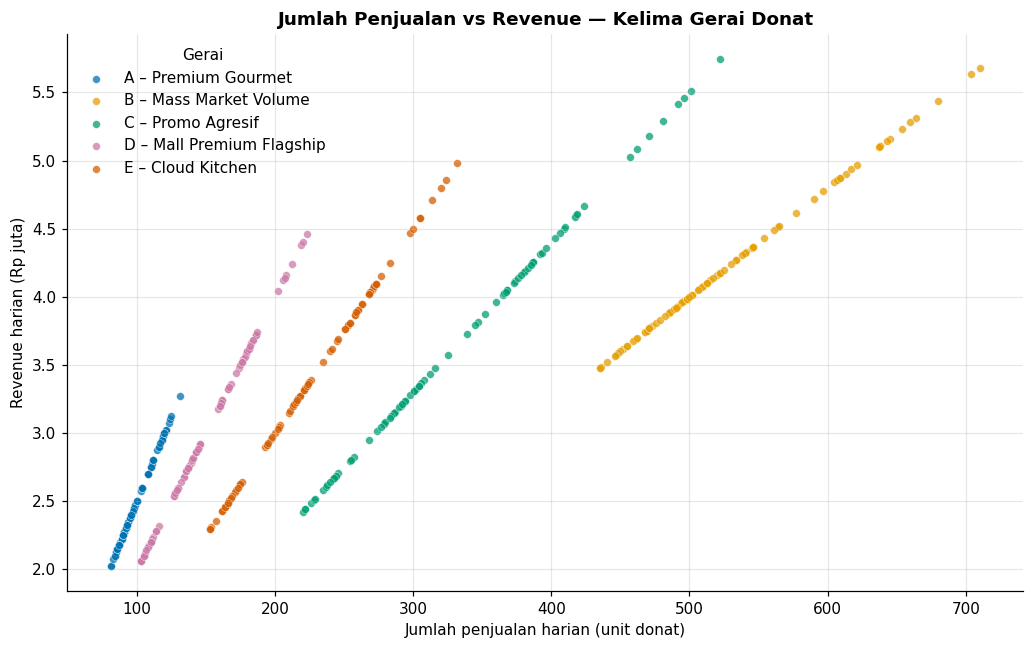

In [123]:
rupiah_juta = FuncFormatter(lambda x, _: f"{x:,.1f}")

fig, ax = plt.subplots(figsize=(9.5, 6))
for g in GERAI:
    d = data[data.Gerai == g]
    ax.scatter(d.Q, d.Revenue / 1e6, s=26, alpha=0.75, color=WARNA[g],
               edgecolor="white", linewidth=0.3, label=NAMA[g])
ax.set_xlabel("Jumlah penjualan harian (unit donat)")
ax.set_ylabel("Revenue harian (Rp juta)")
ax.set_title("Jumlah Penjualan vs Revenue — Kelima Gerai Donat", fontweight="bold")
ax.legend(title="Gerai", frameon=False)
plt.tight_layout()
plt.show()

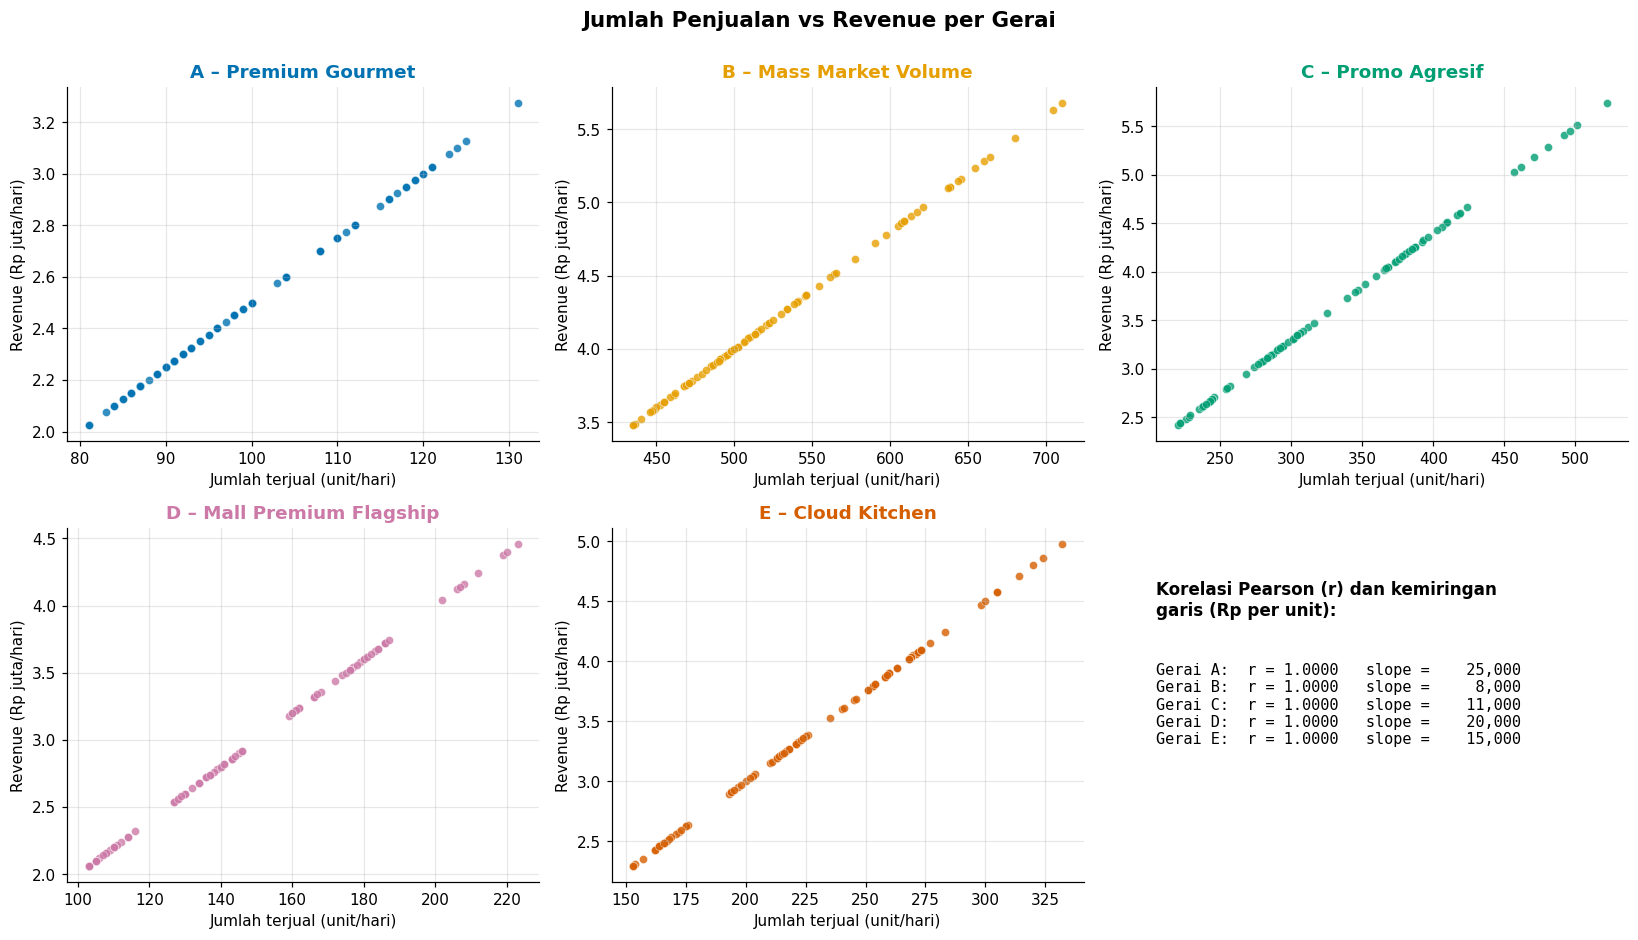

In [124]:
# ---------- Gambar 2: panel per gerai ----------
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.ravel()
for ax, g in zip(axes, GERAI):
    d = data[data.Gerai == g]
    ax.scatter(d.Q, d.Revenue / 1e6, s=28, alpha=0.8, color=WARNA[g], edgecolor="white", linewidth=0.3)
    ax.set_title(NAMA[g], fontweight="bold", color=WARNA[g])
    ax.set_xlabel("Jumlah terjual (unit/hari)")
    ax.set_ylabel("Revenue (Rp juta/hari)")

# panel ke-6: ringkasan korelasi & kemiringan
ringkas = []
for g in GERAI:
    d = data[data.Gerai == g]
    lr = stats.linregress(d.Q, d.Revenue)
    ringkas.append(f"{g}:  r = {lr.rvalue:.4f}   slope = {lr.slope:>9,.0f}")
axes[5].axis("off")
axes[5].text(0.0, 0.85, "Korelasi Pearson (r) dan kemiringan\ngaris (Rp per unit):",
             fontsize=11, fontweight="bold", va="top")
axes[5].text(0.0, 0.62, "\n".join(ringkas), family="monospace", fontsize=10, va="top")
fig.suptitle("Jumlah Penjualan vs Revenue per Gerai", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

In [125]:
# tabel pendukung: korelasi dan rentang data
rows = []
for g in GERAI:
    d = data[data.Gerai == g]
    r, _ = stats.pearsonr(d.Q, d.Revenue)
    rows.append({"Gerai": g, "Q min": d.Q.min(), "Q maks": d.Q.max(),
                 "Revenue min (Rp)": d.Revenue.min(), "Revenue maks (Rp)": d.Revenue.max(),
                 "Korelasi r": f"{r:.6f}"})
pd.DataFrame(rows).set_index("Gerai")

,Q min,Q maks,Revenue min (Rp),Revenue maks (Rp),Korelasi r
Gerai,,,,,
Gerai A,81,131,2025000,3275000,1.000000
Gerai B,435,710,3480000,5680000,1.000000
Gerai C,220,522,2420000,5742000,1.000000
Gerai D,103,223,2060000,4460000,1.000000
Gerai E,153,332,2295000,4980000,1.000000


**Interpretasi Langkah 1**

- Pada **semua gerai**, titik-titik data tersusun **tepat pada satu garis lurus yang melewati titik asal** (korelasi $r = 1$). Semakin banyak donat terjual, revenue naik secara proporsional.
- **Kemiringan garis = harga jual per unit.** Gerai A (Rp 25.000) memiliki garis paling curam, disusul D (Rp 20.000), E (Rp 15.000), C (Rp 11.000), dan B (Rp 8.000) yang paling landai.
- Perbedaan strategi terlihat pada **posisi dan sebaran titik** di sumbu-x:
  - **B (mass market)** menjual volume terbesar (sekitar 435–710 unit/hari) dengan harga rendah.
  - **A (premium)** dan **D (mall premium)** menjual volume kecil (sekitar 81–131 dan 103–223 unit/hari) tetapi dengan harga tinggi.
  - **C (promo agresif)** memiliki sebaran volume paling lebar secara relatif (sekitar 220–522 unit/hari), konsisten dengan sifat promo yang membuat penjualan berfluktuasi.
- Grafik ini hanya menunjukkan *revenue*, belum *laba*. Apakah suatu gerai untung atau rugi ditentukan oleh perbandingan revenue dengan biaya akan dibahas Langkah 3.

---
# Langkah 2 — Regresi: Bentuk Tren Revenue terhadap Volume Penjualan

## 2.1 Model kandidat

Untuk **setiap gerai**, enam model dicocokkan ke data $(q_i, R_i)$, dengan $q$ = jumlah terjual dan $R$ = revenue:

| # | Model | Bentuk | Jumlah parameter ($k$) | Metode estimasi |
|---|---|---|---|---|
| 1 | Linear melalui titik asal | $R = a\,q$ | 1 | *Least squares* bentuk tertutup, $a=\sum q_iR_i / \sum q_i^2$ |
| 2 | Linear | $R = c_0 + c_1 q$ | 2 | OLS (`Polynomial.fit`) |
| 3 | Polinomial derajat 2 | $R = c_0 + c_1 q + c_2 q^2$ | 3 | OLS (`Polynomial.fit`) |
| 4 | Polinomial derajat 3 | $R = c_0 + c_1 q + c_2 q^2 + c_3 q^3$ | 4 | OLS (`Polynomial.fit`) |
| 5 | Power (pangkat) | $R = a\,q^{b}$ | 2 | Non-linear (`curve_fit`), tebakan awal dari regresi log–log |
| 6 | Eksponensial | $R = a\,e^{bq}$ | 2 | Non-linear (`curve_fit`), tebakan awal dari regresi semi-log |

## 2.2 Kriteria evaluasi dan aturan pemilihan model

Untuk setiap model dihitung (dengan $n$ = jumlah data, $\hat R_i$ = prediksi):

$$R^2 = 1-\frac{\sum (R_i-\hat R_i)^2}{\sum (R_i-\bar R)^2},\qquad
R^2_{adj} = 1-(1-R^2)\frac{n-1}{n-k-1},\qquad
\text{RMSE}=\sqrt{\frac{1}{n}\sum (R_i-\hat R_i)^2}$$

serta MAPE (rata-rata persentase galat absolut).

**Aturan pemilihan (prinsip *parsimony*):** dari semua model yang galatnya praktis sama baiknya (RMSE tidak lebih dari **Rp 1** di atas RMSE terkecil, karena Rp 1 adalah satuan mata uang terkecil), dipilih model dengan **parameter paling sedikit**. Model yang lebih rumit tidak dipilih jika tidak memberi perbaikan yang berarti (menghindari *overfitting*).

In [126]:
# ------------------------------------------------------------------
# Data per gerai
# ------------------------------------------------------------------
q_all = {g: data.loc[data.Gerai == g, "Q"].to_numpy(float) for g in GERAI}
rev_all = {g: data.loc[data.Gerai == g, "Revenue"].to_numpy(float) for g in GERAI}
cost_all = {g: data.loc[data.Gerai == g, "TotalCost"].to_numpy(float) for g in GERAI}

# ------------------------------------------------------------------
# Fungsi fitting: masing-masing mengembalikan (fungsi_prediksi, parameter, k)
# ------------------------------------------------------------------
def fit_linear_origin(q, y):
    a = np.sum(q * y) / np.sum(q * q)
    return (lambda x: a * np.asarray(x, float)), {"a": a}, 1

def fit_poly(q, y, deg):
    p = Polynomial.fit(q, y, deg)             # domain diskalakan -> stabil secara numerik
    coef = p.convert().coef                   # koefisien pada variabel asli q
    return p, {f"c{i}": c for i, c in enumerate(coef)}, deg + 1

def fit_power(q, y):
    b0, ln_a0 = np.polyfit(np.log(q), np.log(y), 1)      # ln y = ln a + b ln q
    f = lambda x, a, b: a * np.power(x, b)
    (a, b), _ = curve_fit(f, q, y, p0=[np.exp(ln_a0), b0], maxfev=50000)
    return (lambda x: f(np.asarray(x, float), a, b)), {"a": a, "b": b}, 2

def fit_exp(q, y):
    b0, ln_a0 = np.polyfit(q, np.log(y), 1)               # ln y = ln a + b q
    f = lambda x, a, b: a * np.exp(b * x)
    (a, b), _ = curve_fit(f, q, y, p0=[np.exp(ln_a0), b0], maxfev=50000)
    return (lambda x: f(np.asarray(x, float), a, b)), {"a": a, "b": b}, 2

MODEL_FITTERS = {
    "Linear (titik asal)":   fit_linear_origin,
    "Linear":                lambda q, y: fit_poly(q, y, 1),
    "Polinomial deg 2":      lambda q, y: fit_poly(q, y, 2),
    "Polinomial deg 3":      lambda q, y: fit_poly(q, y, 3),
    "Power":                 fit_power,
    "Eksponensial":          fit_exp,
}

def metrics(y, yhat, k):
    n = len(y)
    sse = np.sum((y - yhat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    r2 = 1 - sse / sst
    return {
        "R2": r2,
        "R2_adj": 1 - (1 - r2) * (n - 1) / (n - k - 1),
        "RMSE": np.sqrt(sse / n),
        "MAPE": np.mean(np.abs((y - yhat) / y)) * 100,
    }

def fmt_err(x):
    return f"{x:.3e}" if x < 1 else f"{x:,.2f}"

# ------------------------------------------------------------------
# Fitting semua model untuk semua gerai
# ------------------------------------------------------------------
fits = {}
for g in GERAI:
    fits[g] = {}
    for nama_model, fitter in MODEL_FITTERS.items():
        pred, params, k = fitter(q_all[g], rev_all[g])
        m = metrics(rev_all[g], pred(q_all[g]), k)
        fits[g][nama_model] = {"pred": pred, "params": params, "k": k, **m}

def tabel_model(g):
    rows = []
    for nama_model, r in fits[g].items():
        rows.append({"Model": nama_model, "k": r["k"],
                     "R²": f"{r['R2']:.8f}", "R² adj": f"{r['R2_adj']:.8f}",
                     "RMSE (Rp)": fmt_err(r["RMSE"]), "MAPE (%)": fmt_err(r["MAPE"])})
    return pd.DataFrame(rows).set_index("Model")

print("Regresi selesai untuk", len(GERAI), "gerai x", len(MODEL_FITTERS), "model.")

Regresi selesai untuk 5 gerai x 6 model.


## 2.3 Hasil perbandingan model per gerai

In [127]:
print("Gerai A — {}".format(NAMA["Gerai A"]))
tabel_model("Gerai A")

Gerai A — A – Premium Gourmet


,k,R²,R² adj,RMSE (Rp),MAPE (%)
Model,,,,,
Linear (titik asal),1,1.00000000,1.00000000,0.000e+00,0.000e+00
Linear,2,1.00000000,1.00000000,8.846e-10,3.611e-14
Polinomial deg 2,3,1.00000000,1.00000000,4.935e-09,1.201e-13
Polinomial deg 3,4,1.00000000,1.00000000,1.468e-09,5.393e-14
Power,2,1.00000000,1.00000000,1.116e-09,4.374e-14
Eksponensial,2,0.99694790,0.99687773,"17,161.88",5.425e-01


In [128]:
print("Gerai B — {}".format(NAMA["Gerai B"]))
tabel_model("Gerai B")

Gerai B — B – Mass Market Volume


,k,R²,R² adj,RMSE (Rp),MAPE (%)
Model,,,,,
Linear (titik asal),1,1.00000000,1.00000000,0.000e+00,0.000e+00
Linear,2,1.00000000,1.00000000,9.261e-10,2.016e-14
Polinomial deg 2,3,1.00000000,1.00000000,1.014e-08,1.572e-13
Polinomial deg 3,4,1.00000000,1.00000000,5.309e-10,9.117e-15
Power,2,1.00000000,1.00000000,1.937e-09,4.549e-14
Eksponensial,2,0.99582896,0.99573307,"35,244.76",6.665e-01


In [129]:
print("Gerai C — {}".format(NAMA["Gerai C"]))
tabel_model("Gerai C")

Gerai C — C – Promo Agresif


,k,R²,R² adj,RMSE (Rp),MAPE (%)
Model,,,,,
Linear (titik asal),1,1.00000000,1.00000000,0.000e+00,0.000e+00
Linear,2,1.00000000,1.00000000,7.028e-10,1.180e-14
Polinomial deg 2,3,1.00000000,1.00000000,1.264e-09,3.550e-14
Polinomial deg 3,4,1.00000000,1.00000000,2.074e-09,6.050e-14
Power,2,1.00000000,1.00000000,0.000e+00,0.000e+00
Eksponensial,2,0.98590425,0.98558021,"100,155.24",2.42


In [130]:
print("Gerai D — {}".format(NAMA["Gerai D"]))
tabel_model("Gerai D")

Gerai D — D – Mall Premium Flagship


,k,R²,R² adj,RMSE (Rp),MAPE (%)
Model,,,,,
Linear (titik asal),1,1.00000000,1.00000000,0.000e+00,0.000e+00
Linear,2,1.00000000,1.00000000,6.801e-10,2.091e-14
Polinomial deg 2,3,1.00000000,1.00000000,1.019e-09,3.069e-14
Polinomial deg 3,4,1.00000000,1.00000000,8.330e-10,1.358e-14
Power,2,1.00000000,1.00000000,5.241e-10,1.729e-14
Eksponensial,2,0.98817665,0.98790485,"71,460.18",2.18


In [131]:
print("Gerai E — {}".format(NAMA["Gerai E"]))
tabel_model("Gerai E")

Gerai E — E – Cloud Kitchen


,k,R²,R² adj,RMSE (Rp),MAPE (%)
Model,,,,,
Linear (titik asal),1,1.00000000,1.00000000,0.000e+00,0.000e+00
Linear,2,1.00000000,1.00000000,1.785e-09,4.836e-14
Polinomial deg 2,3,1.00000000,1.00000000,2.281e-09,6.393e-14
Polinomial deg 3,4,1.00000000,1.00000000,2.454e-10,2.191e-15
Power,2,1.00000000,1.00000000,8.416e-10,2.402e-14
Eksponensial,2,0.98872460,0.98846540,"74,100.29",1.98


## 2.4 Memilih model terbaik (aturan *parsimony*)

In [132]:
TOL_RMSE = 1.0   # Rp; RMSE yang selisihnya di bawah Rp 1 dianggap setara

best = {}
rows = []
for g in GERAI:
    hasil = pd.DataFrame(fits[g]).T[["k", "RMSE", "R2"]].astype(float)
    rmse_min = hasil["RMSE"].min()
    kandidat = hasil[hasil["RMSE"] <= rmse_min + TOL_RMSE]          # model yang "setara baik"
    terpilih = kandidat.sort_values(["k", "RMSE"]).index[0]         # yang paling sederhana
    best[g] = terpilih
    a = fits[g][terpilih]["params"]["a"]
    rows.append({
        "Gerai": g,
        "Model terpilih": terpilih,
        "Persamaan R(q)": f"R(q) = {a:,.2f} · q",
        "R²": f"{fits[g][terpilih]['R2']:.6f}",
        "RMSE (Rp)": fmt_err(fits[g][terpilih]["RMSE"]),
        "Harga jual di data (Rp)": int(param.loc[g, "Harga"]),
    })
    setara = ", ".join(kandidat.index)
    print(f"{g}: model dengan galat setara = {setara}")
pd.DataFrame(rows).set_index("Gerai")

Gerai A: model dengan galat setara = Linear (titik asal), Linear, Polinomial deg 2, Polinomial deg 3, Power
Gerai B: model dengan galat setara = Linear (titik asal), Linear, Polinomial deg 2, Polinomial deg 3, Power
Gerai C: model dengan galat setara = Linear (titik asal), Linear, Polinomial deg 2, Polinomial deg 3, Power
Gerai D: model dengan galat setara = Linear (titik asal), Linear, Polinomial deg 2, Polinomial deg 3, Power
Gerai E: model dengan galat setara = Linear (titik asal), Linear, Polinomial deg 2, Polinomial deg 3, Power


,Model terpilih,Persamaan R(q),R²,RMSE (Rp),Harga jual di data (Rp)
Gerai,,,,,
Gerai A,Linear (titik asal),"R(q) = 25,000.00 · q",1.000000,0.000e+00,25000
Gerai B,Linear (titik asal),"R(q) = 8,000.00 · q",1.000000,0.000e+00,8000
Gerai C,Linear (titik asal),"R(q) = 11,000.00 · q",1.000000,0.000e+00,11000
Gerai D,Linear (titik asal),"R(q) = 20,000.00 · q",1.000000,0.000e+00,20000
Gerai E,Linear (titik asal),"R(q) = 15,000.00 · q",1.000000,0.000e+00,15000


In [133]:
# Bukti tambahan bahwa bentuknya linear proporsional (bukan kurva)
bukti = []
for g in GERAI:
    p2 = fits[g]["Polinomial deg 2"]["params"]
    p3 = fits[g]["Polinomial deg 3"]["params"]
    lin = fits[g]["Linear"]["params"]
    bukti.append({
        "Gerai": g,
        "Intercept model linear (Rp)": f"{lin['c0']:.2e}",
        "Koef. q² (deg 2)": f"{p2['c2']:.2e}",
        "Koef. q³ (deg 3)": f"{p3.get('c3', 0.0):.2e}", # Fixed: Use .get() with a default value
        "Eksponen b (Power)": f"{fits[g]['Power']['params']['b']:.6f}",
        "R² Eksponensial": f"{fits[g]['Eksponensial']['R2']:.6f}",
    })
pd.DataFrame(bukti).set_index("Gerai")

,Intercept model linear (Rp),Koef. q² (deg 2),Koef. q³ (deg 3),Eksponen b (Power),R² Eksponensial
Gerai,,,,,
Gerai A,1.86e-09,5.77e-12,-1.40e-13,1.000000,0.996948
Gerai B,4.66e-09,3.32e-13,-4.94e-16,1.000000,0.995829
Gerai C,1.40e-09,3.76e-14,1.81e-16,1.000000,0.985904
Gerai D,0.00e+00,5.61e-14,5.72e-15,1.000000,0.988177
Gerai E,4.66e-10,-2.82e-14,0.00e+00,1.000000,0.988725


## 2.5 Visualisasi kecocokan semua model

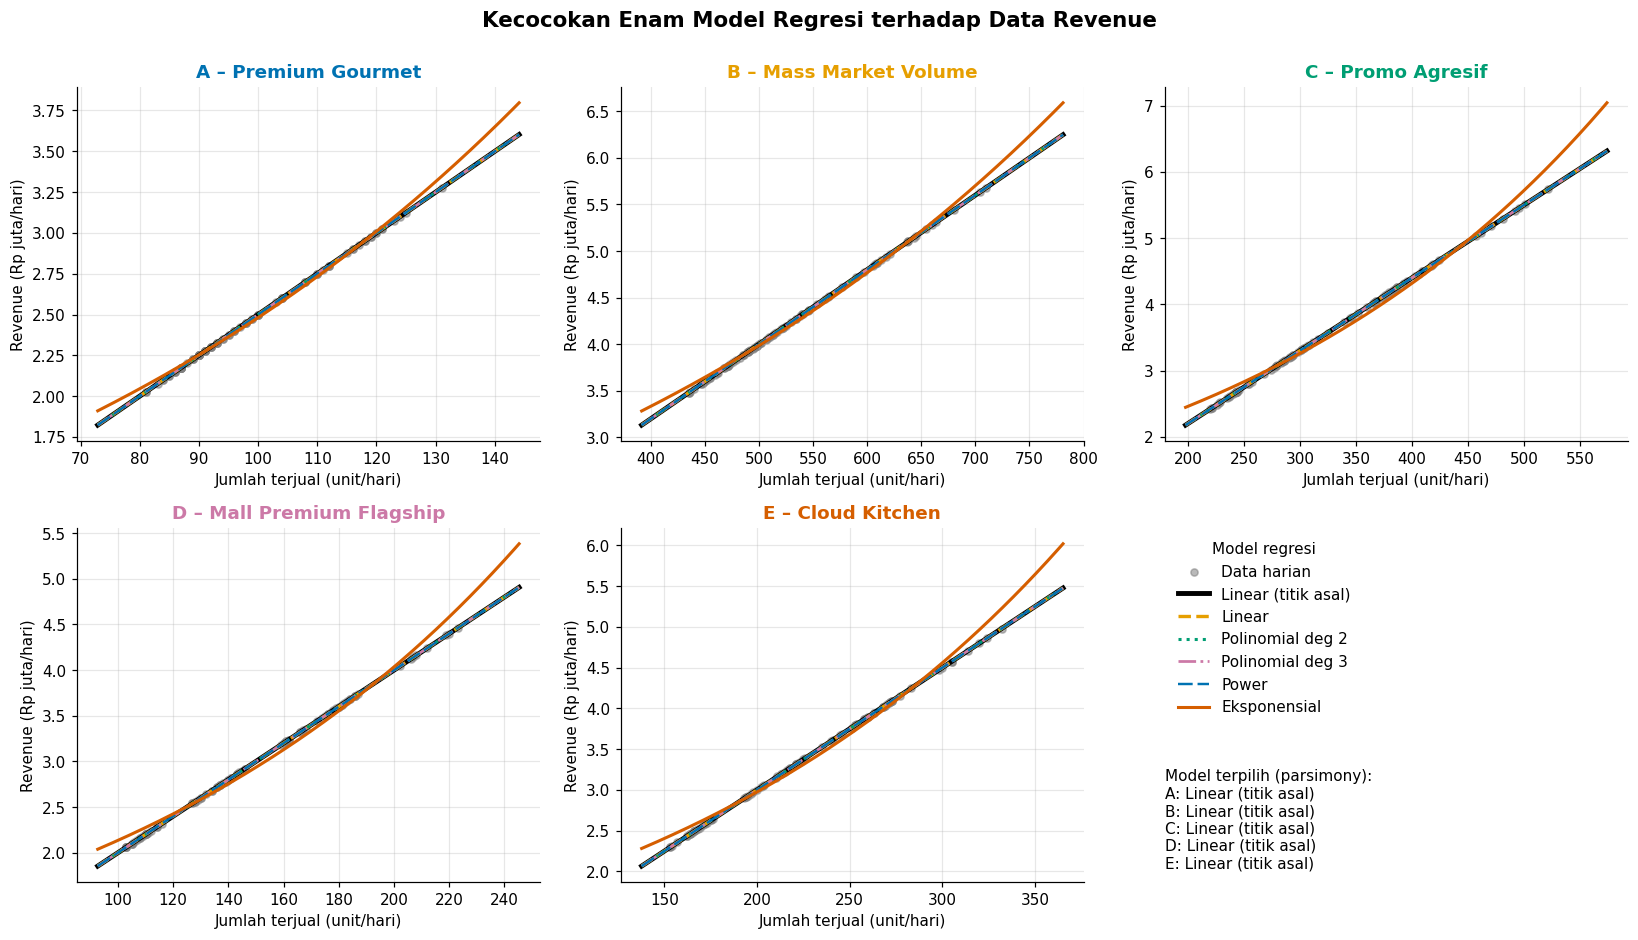

In [134]:
STYLE = {
    "Linear (titik asal)": dict(color="#000000", lw=3.2, ls="-"),
    "Linear":              dict(color="#E69F00", lw=2.2, ls="--"),
    "Polinomial deg 2":    dict(color="#009E73", lw=2.0, ls=":"),
    "Polinomial deg 3":    dict(color="#CC79A7", lw=1.8, ls="-."),
    "Power":               dict(color="#0072B2", lw=1.6, ls=(0, (6, 2))),
    "Eksponensial":        dict(color="#D55E00", lw=2.0, ls="-"),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.ravel()
for ax, g in zip(axes, GERAI):
    q, y = q_all[g], rev_all[g]
    qq = np.linspace(q.min() * 0.9, q.max() * 1.1, 300)
    ax.scatter(q, y / 1e6, s=22, color="gray", alpha=0.55, label="Data harian", zorder=1)
    for nama_model, st in STYLE.items():
        ax.plot(qq, fits[g][nama_model]["pred"](qq) / 1e6, label=nama_model, **st)
    ax.set_title(NAMA[g], fontweight="bold", color=WARNA[g])
    ax.set_xlabel("Jumlah terjual (unit/hari)")
    ax.set_ylabel("Revenue (Rp juta/hari)")

handles, labels = axes[0].get_legend_handles_labels()
axes[5].axis("off")
axes[5].legend(handles, labels, loc="upper left", frameon=False, fontsize=10, title="Model regresi")
teks = ("Model terpilih (parsimony):\n" +
        "\n".join(f"{g[-1]}: {best[g]}" for g in GERAI))
axes[5].text(0.0, 0.32, teks, fontsize=10, va="top")
fig.suptitle("Kecocokan Enam Model Regresi terhadap Data Revenue", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

**Interpretasi Langkah 2**

- **Semua model yang mampu membentuk garis lurus** (linear, polinomial derajat 2 dan 3, serta power) cocok hampir sempurna pada setiap gerai. Nilai $R^2 = 1$ dan RMSE hanya berorde $10^{-9}$ Rp atau lebih kecil (praktis hanya galat pembulatan bilangan desimal komputer), jauh di bawah satuan mata uang terkecil. Pada grafik, kurva-kurva ini saling menumpuk.
- Bukti bahwa tren sebenarnya **linear proporsional**:
  - intercept model linear $\approx 0$, artinya tanpa penjualan tidak ada revenue;
  - koefisien $q^2$ dan $q^3$ pada polinomial $\approx 0$, artinya tidak ada lengkungan;
  - eksponen model power $b = 1{,}000000$, artinya revenue berbanding lurus dengan $q$.
- **Model eksponensial** adalah satu-satunya yang secara nyata lebih buruk (RMSE sekitar Rp 17 ribu hingga Rp 100 ribu, dan $R^2$ antara 0,986 dan 0,997). Ini wajar karena revenue tumbuh dengan laju tetap, bukan dengan laju yang makin membesar seperti pola eksponensial; pada grafik kurva eksponensial melengkung menjauhi data.
- Karena banyak model memberi galat yang setara, kita pakai aturan *parsimony*. Model terpilih untuk **semua gerai** adalah **Linear melalui titik asal**, $R(q) = p \cdot q$, dan koefisiennya identik dengan harga jual tiap gerai (Rp 25.000; 8.000; 11.000; 20.000; 15.000).
- **Catatan:** kecocokan yang sempurna (galat mendekati nol) terjadi karena data sintetis ini memakai harga tetap, sehingga $\text{revenue} = \text{harga} \times \text{jumlah}$ secara pasti. Pada data nyata yang mengandung diskon atau harga bervariasi, kita akan melihat sebaran di sekitar garis dan $R^2 < 1$.

---
# Langkah 3 — Volume Penjualan pada *Breakeven Point* (BEP)

## 3.1 Definisi dan model biaya

*Breakeven point* adalah volume penjualan $q^*$ ketika **revenue sama dengan total biaya**:

$$R(q^*) = C(q^*) \quad\Longleftrightarrow\quad f(q^*) = R(q^*) - C(q^*) = 0$$

- $R(q)$ diambil dari **hasil regresi Langkah 2** (model terpilih tiap gerai).
- $C(q)$ adalah total biaya harian $= $ biaya variabel + *fixed cost*. Agar konsisten dengan pendekatan regresi, $C(q)$ juga diperoleh dengan **regresi linear** $C(q) = c_0 + c_1 q$ dari data `TotalCost` terhadap `Q`.
  Secara teori $c_0 \approx FC$ (biaya tetap harian) dan $c_1 \approx v$ (biaya variabel per unit).

Untuk model linear, solusi analitiknya adalah
$$q^* = \frac{c_0 - r_0}{r_1 - c_1}$$
(dengan $R(q) = r_0 + r_1 q$). Solusi ini dipakai sebagai **pembanding**, sedangkan penyelesaian utamanya menggunakan **metode numerik pencarian akar** sesuai konteks mata kuliah Analisis Numerik.

## 3.2 Regresi total biaya

In [135]:
import math
from IPython.display import Markdown # Added import for Markdown

def tex_num(x, pm_eps=1e-6):
    # Return LaTeX string for a number, omit +/- sign if within eps
    if abs(x) < pm_eps: return "0"
    return f"{x:,.0f}"

def poly_tex(coefs, var="q", pm_eps=1e-6):
    # Return LaTeX string for a polynomial from given coefficients
    out = []
    for i, c in enumerate(coefs):
        if abs(c) < pm_eps: continue
        if i == 0: out.append(f"{tex_num(c, pm_eps)}")
        elif i == 1: out.append(f"{tex_num(c, pm_eps)}\,{var}")
        else: out.append(f"{tex_num(c, pm_eps)}\,{var}^{i}")
    return " + ".join(out).replace("+ -", "-")

cost_fits = {}
rows = []
for g in GERAI:
    q, y = q_all[g], cost_all[g]
    p = Polynomial.fit(q, y, 1)
    c0, c1 = p.convert().coef
    m = metrics(y, p(q), 2)
    cost_fits[g] = {"pred": p, "c0": c0, "c1": c1, **m}
    rows.append({
        "Gerai": g,
        "Intercept c0 (Rp)": f"{c0:,.2f}",
        "Fixed cost data (Rp)": f"{param.loc[g, 'FC_harian']:,.0f}",
        "Slope c1 (Rp/unit)": f"{c1:,.4f}",
        "VC/unit data (Rp)": f"{param.loc[g, 'VC_per_unit']:,.2f}",
        "R²": f"{m['R2']:.6f}",
    })
display(pd.DataFrame(rows).set_index("Gerai"))

# persamaan regresi biaya dan laba harian L(q) = R(q) - C(q)
baris = ["| Gerai | Persamaan total biaya C(q) | Laba harian L(q) = R(q) − C(q) |", "|---|---|---|"]
for g in GERAI:
    c0, c1 = cost_fits[g]["c0"], cost_fits[g]["c1"]
    a = fits[g][best[g]]["params"]["a"]
    baris.append(f"| {g} | $C(q) = {poly_tex([c0, c1])}$ | $L(q) = {tex_num(a - c1)}\,q - {tex_num(c0)}$ |")
print("\n")
display(Markdown("\n".join(baris)))

,Intercept c0 (Rp),Fixed cost data (Rp),Slope c1 (Rp/unit),VC/unit data (Rp),R²
Gerai,,,,,
Gerai A,"1,683,333.00","1,683,333","8,500.0000","8,500.00",1.000000
Gerai B,"733,333.00","733,333","4,160.0000","4,160.00",1.000000
Gerai C,"1,733,333.00","1,733,333","4,840.0000","4,840.00",1.000000
Gerai D,"2,666,666.00","2,666,666","7,200.0000","7,200.00",1.000000
Gerai E,"800,000.00","800,000","6,300.0000","6,300.00",1.000000


| Gerai | Persamaan total biaya C(q) | Laba harian L(q) = R(q) − C(q) |
|---|---|---|
| Gerai A | $C(q) = 1,683,333 + 8,500\,q$ | $L(q) = 16,500\,q - 1,683,333$ |
| Gerai B | $C(q) = 733,333 + 4,160\,q$ | $L(q) = 3,840\,q - 733,333$ |
| Gerai C | $C(q) = 1,733,333 + 4,840\,q$ | $L(q) = 6,160\,q - 1,733,333$ |
| Gerai D | $C(q) = 2,666,666 + 7,200\,q$ | $L(q) = 12,800\,q - 2,666,666$ |
| Gerai E | $C(q) = 800,000 + 6,300\,q$ | $L(q) = 8,700\,q - 800,000$ |

Regresi biaya menghasilkan intercept yang sama dengan *fixed cost* harian dan slope yang sama dengan biaya variabel per unit ($R^2 = 1$), sehingga model $C(q) = FC + v\,q$ valid.


## 3.3 Metode numerik pencarian akar

Tiga metode diterapkan pada $f(q) = R(q) - C(q)$:

1. **Bisection (bagi dua)** — implementasi sendiri, dengan interval awal $[0,\ 2\,q_{maks}]$ dan toleransi lebar interval $10^{-8}$ unit.
2. **Newton–Raphson** — implementasi sendiri, dengan turunan numerik (selisih pusat), tebakan awal = rata-rata penjualan harian.
3. **Brent** (`scipy.optimize.brentq`) — sebagai pembanding dari library.

Hasilnya dibandingkan dengan solusi analitik.

In [136]:
def bisection(f, lo, hi, tol=1e-8, max_iter=200):
    # Metode bisection. Mengembalikan (akar, jumlah_iterasi, riwayat).
    flo, fhi = f(lo), f(hi)
    if flo * fhi > 0:
        raise ValueError("f(lo) dan f(hi) harus berbeda tanda")
    riwayat = []
    for i in range(1, max_iter + 1):
        mid = 0.5 * (lo + hi)
        fmid = f(mid)
        riwayat.append({"iterasi": i, "a": lo, "b": hi, "c (tengah)": mid, "f(c)": fmid})
        if fmid == 0 or 0.5 * (hi - lo) < tol:
            break
        if flo * fmid < 0:
            hi, fhi = mid, fmid
        else:
            lo, flo = mid, fmid
    return mid, i, pd.DataFrame(riwayat)

def newton(f, x0, tol=1e-10, max_iter=50, h=1e-3):
    # Newton-Raphson dengan turunan numerik (selisih pusat).
    x = x0
    for i in range(1, max_iter + 1):
        d = (f(x + h) - f(x - h)) / (2 * h)
        x_baru = x - f(x) / d
        if abs(x_baru - x) < tol:
            return x_baru, i
        x = x_baru
    return x, max_iter

# fungsi R(q) dan C(q) dari hasil regresi
R_fun = {g: fits[g][best[g]]["pred"] for g in GERAI}
C_fun = {g: cost_fits[g]["pred"] for g in GERAI}

rows, q_star = [], {}
for g in GERAI:
    f = lambda q, g=g: R_fun[g](q) - C_fun[g](q)
    lo, hi = 0.0, 2 * q_all[g].max()
    assert f(lo) < 0 < f(hi), "Interval tidak mengurung akar"

    # solusi analitik dari regresi linear (pembanding)
    r0, r1 = fits[g]["Linear"]["params"]["c0"], fits[g]["Linear"]["params"]["c1"]
    q_an = (cost_fits[g]["c0"] - r0) / (r1 - cost_fits[g]["c1"])

    q_bis, it_bis, _ = bisection(f, lo, hi)
    q_nw, it_nw = newton(f, q_all[g].mean())
    q_br = brentq(f, lo, hi, xtol=1e-12)

    q_star[g] = q_nw
    rows.append({
        "Gerai": g,
        "Analitik": f"{q_an:.6f}",
        "Bisection": f"{q_bis:.6f}",
        "Iter. bisection": it_bis,
        "Newton": f"{q_nw:.6f}",
        "Iter. Newton": it_nw,
        "Brent (scipy)": f"{q_br:.6f}",
        "Selisih maks": f"{max(abs(q_bis - q_an), abs(q_nw - q_an), abs(q_br - q_an)):.1e}",
    })
print("BEP (unit donat per hari) menurut tiap metode:")
pd.DataFrame(rows).set_index("Gerai")

BEP (unit donat per hari) menurut tiap metode:


,Analitik,Bisection,Iter. bisection,Newton,Iter. Newton,Brent (scipy),Selisih maks
Gerai,,,,,,,
Gerai A,102.020182,102.020182,35,102.020182,2,102.020182,4.3e-09
Gerai B,190.972135,190.972135,38,190.972135,3,190.972135,2.8e-09
Gerai C,281.385227,281.385227,37,281.385227,3,281.385227,7.2e-09
Gerai D,208.333281,208.333281,36,208.333281,3,208.333281,2.2e-09
Gerai E,91.954023,91.954023,36,91.954023,3,91.954023,2.0e-09


Keempat cara (analitik, bisection, Newton–Raphson, Brent) menghasilkan nilai BEP yang sama; selisih terbesarnya di bawah $10^{-8}$ unit (kolom *Selisih maks*), yaitu galat toleransi/pembulatan. Karena $f(q)$ berbentuk linear, Newton–Raphson konvergen hanya dalam 2–3 iterasi (langkah pertama sudah tepat, langkah berikutnya hanya memastikan konvergensi), sedangkan bisection membutuhkan sekitar 35–38 iterasi.

Sebagai ilustrasi jalannya algoritma, berikut iterasi awal metode bisection untuk **Gerai A**:

In [137]:
gA = "Gerai A"
fA = lambda q: R_fun[gA](q) - C_fun[gA](q)
_, _, riwayat_A = bisection(fA, 0.0, 2 * q_all[gA].max())
riwayat_A.head(12)

,iterasi,a,b,c (tengah),f(c)
0,1,0.00,262.00,131.00,"478,167.00"
1,2,0.00,131.00,65.50,"-602,583.00"
2,3,65.50,131.00,98.25,"-62,208.00"
3,4,98.25,131.00,114.62,"207,979.50"
4,5,98.25,114.62,106.44,"72,885.75"
5,6,98.25,106.44,102.34,"5,338.87"
6,7,98.25,102.34,100.30,"-28,434.56"
7,8,100.30,102.34,101.32,"-11,547.84"
8,9,101.32,102.34,101.83,"-3,104.48"
9,10,101.83,102.34,102.09,"1,117.20"


## 3.4 BEP dalam satuan praktis dan perbandingan dengan penjualan aktual

Karena donat dijual dalam unit utuh, BEP dibulatkan **ke atas** ke bilangan bulat, yaitu jumlah donat minimum per hari agar tidak rugi. Ditambahkan juga:

- **Revenue pada BEP** = $R(q^*)$,
- **Margin of Safety (MoS)** = $\dfrac{\bar q - q^*}{\bar q}\times 100\%$, dengan $\bar q$ = rata-rata penjualan harian (negatif berarti rata-rata penjualan berada di bawah BEP),
- persentase hari dengan penjualan $\ge q^*$,
- apakah BEP berada di dalam rentang volume yang pernah diamati (jika tidak, hasilnya merupakan ekstrapolasi).

In [138]:
rows = []
for g in GERAI:
    qs = q_star[g]
    q_int = int(np.ceil(qs - 1e-9))
    q_rata = q_all[g].mean()
    rows.append({
        "Gerai": g,
        "BEP (unit, eksak)": qs,
        "BEP (unit/hari, dibulatkan)": q_int,
        "Revenue di BEP (Rp)": R_fun[g](qs),
        "Rata-rata Q aktual": q_rata,
        "MoS (%)": (q_rata - qs) / q_rata * 100,
        "Hari Q ≥ BEP (%)": np.mean(q_all[g] >= qs) * 100,
        "BEP dalam rentang data?": "Ya" if q_all[g].min() <= qs <= q_all[g].max() else "Tidak (ekstrapolasi)",
    })
bep = pd.DataFrame(rows).set_index("Gerai")
tampil = bep.copy()
tampil["BEP (unit, eksak)"] = tampil["BEP (unit, eksak)"].map("{:.3f}".format)
tampil["Revenue di BEP (Rp)"] = tampil["Revenue di BEP (Rp)"].map("{:,.0f}".format)
tampil["Rata-rata Q aktual"] = tampil["Rata-rata Q aktual"].map("{:.1f}".format)
tampil["MoS (%)"] = tampil["MoS (%)"].map("{:+.1f}".format)
tampil["Hari Q ≥ BEP (%)"] = tampil["Hari Q ≥ BEP (%)"].map("{:.1f}".format)
tampil

,"BEP (unit, eksak)","BEP (unit/hari, dibulatkan)",Revenue di BEP (Rp),Rata-rata Q aktual,MoS (%),Hari Q ≥ BEP (%),BEP dalam rentang data?
Gerai,,,,,,,
Gerai A,102.020,103,"2,550,505",99.1,-2.9,34.4,Ya
Gerai B,190.972,191,"1,527,777",527.5,+63.8,100.0,Tidak (ekstrapolasi)
Gerai C,281.385,282,"3,095,238",328.9,+14.5,68.9,Ya
Gerai D,208.333,209,"4,166,666",149.8,-39.0,4.4,Ya
Gerai E,91.954,92,"1,379,310",226.6,+59.4,100.0,Tidak (ekstrapolasi)


### Validasi terhadap data aktual

BEP dari regresi diuji dengan kolom `Balance` pada data. Jika perhitungan benar, hari dengan `Balance` $\ge 0$ harus **persis** hari dengan $Q \ge q^*$.

In [139]:
rows = []
for g in GERAI:
    d = data[data.Gerai == g]
    prediksi_untung = d.Q >= q_star[g]
    aktual_untung = d.Balance >= 0
    q_int = int(np.ceil(q_star[g] - 1e-9))
    rows.append({
        "Gerai": g,
        "Hari untung (aktual)": int(aktual_untung.sum()),
        "Hari untung (prediksi BEP)": int(prediksi_untung.sum()),
        "Akurasi prediksi (%)": (prediksi_untung == aktual_untung).mean() * 100,
        "f(BEP−1) < 0 ?": bool((R_fun[g](q_int - 1) - C_fun[g](q_int - 1)) < 0),
        "f(BEP) ≥ 0 ?": bool((R_fun[g](q_int) - C_fun[g](q_int)) >= 0),
    })
pd.DataFrame(rows).set_index("Gerai")

,Hari untung (aktual),Hari untung (prediksi BEP),Akurasi prediksi (%),f(BEP−1) < 0 ?,f(BEP) ≥ 0 ?
Gerai,,,,,
Gerai A,31,31,100.00,True,True
Gerai B,90,90,100.00,True,True
Gerai C,62,62,100.00,True,True
Gerai D,4,4,100.00,True,True
Gerai E,90,90,100.00,True,True


## 3.5 Visualisasi *breakeven*

Setiap panel menampilkan garis revenue $R(q)$ (hasil regresi Langkah 2), garis total biaya $C(q)$, titik BEP (bulat emas), zona rugi (merah), dan zona laba (hijau).
Titik-titik kecil adalah data harian aktual. Panel ke-6 membandingkan BEP dengan rata-rata penjualan harian tiap gerai.

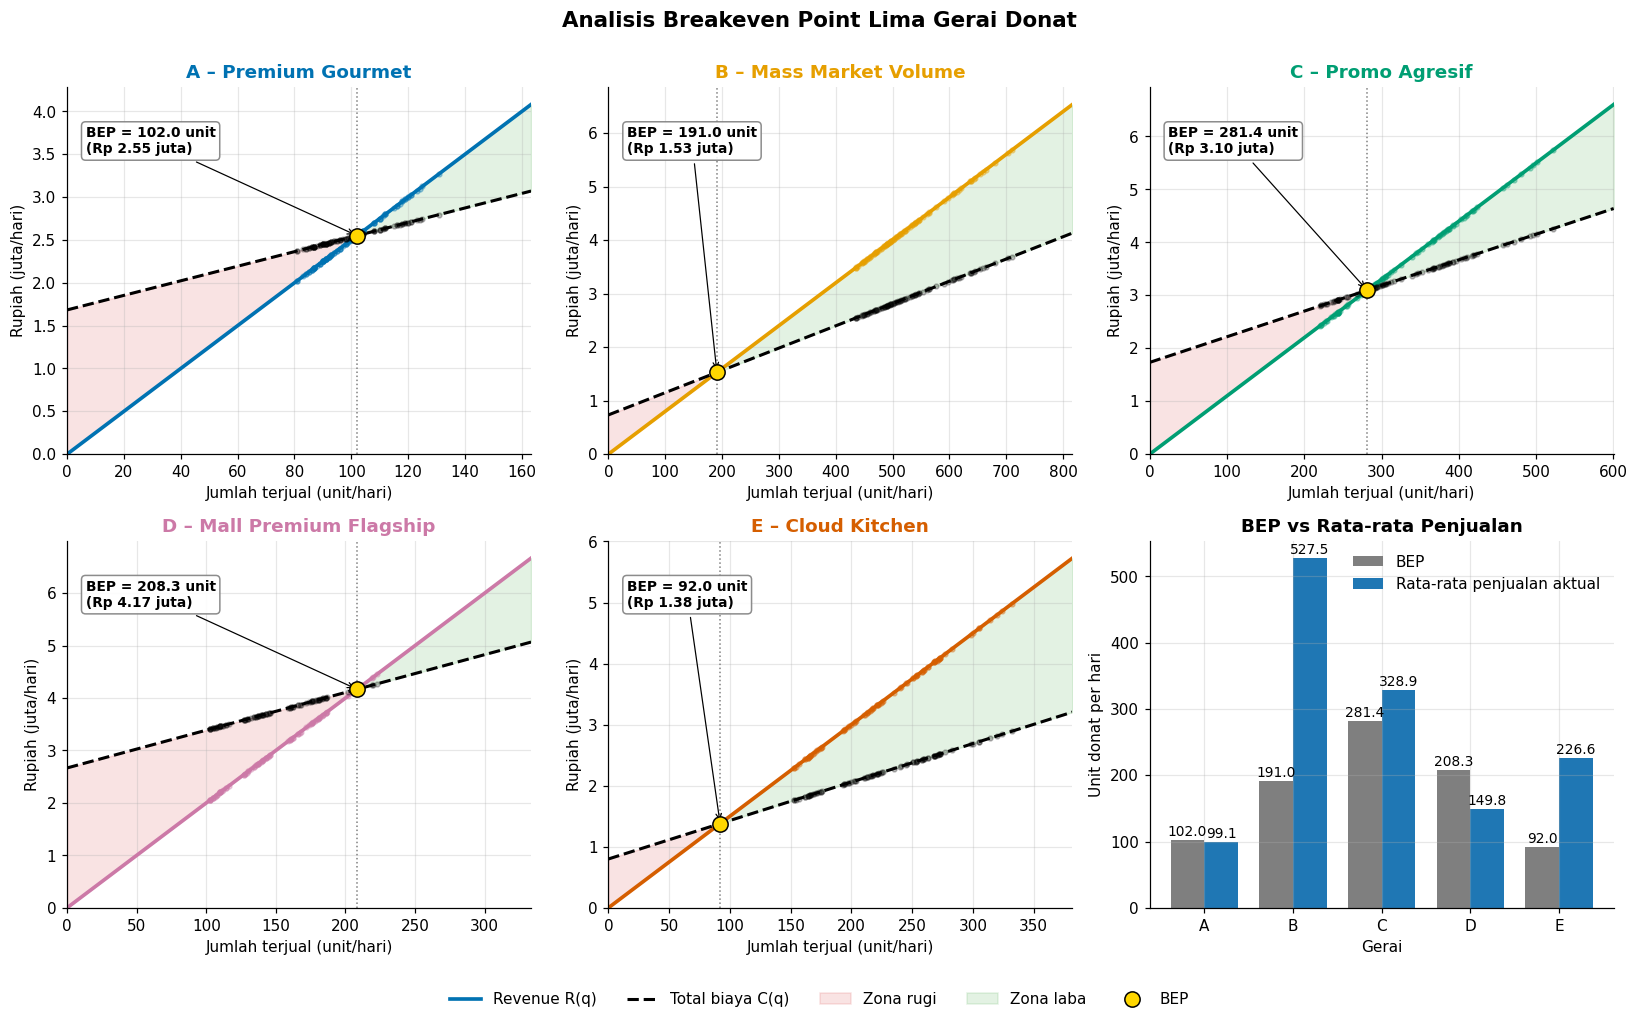

In [140]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, g in zip(axes, GERAI):
    q = q_all[g]
    qs = q_star[g]
    qq = np.linspace(0, max(q.max() * 1.15, qs * 1.6), 400)
    R, C = R_fun[g](qq) / 1e6, C_fun[g](qq) / 1e6

    ax.plot(qq, R, color=WARNA[g], lw=2.4, label="Revenue R(q)")
    ax.plot(qq, C, color="black", lw=2.0, ls="--", label="Total biaya C(q)")
    ax.fill_between(qq, R, C, where=qq <= qs, interpolate=True, color="#d62728", alpha=0.13, label="Zona rugi")
    ax.fill_between(qq, R, C, where=qq >= qs, interpolate=True, color="#2ca02c", alpha=0.13, label="Zona laba")
    ax.scatter(q, rev_all[g] / 1e6, s=10, color=WARNA[g], alpha=0.35, zorder=2)
    ax.scatter(q, cost_all[g] / 1e6, s=10, color="black", alpha=0.25, zorder=2)
    ax.axvline(qs, color="gray", ls=":", lw=1)
    ax.plot(qs, R_fun[g](qs) / 1e6, "o", ms=10, mfc="gold", mec="black", zorder=5, label="BEP")
    ax.annotate(f"BEP = {qs:.1f} unit\n(Rp {R_fun[g](qs)/1e6:.2f} juta)",
                xy=(qs, R_fun[g](qs) / 1e6), xytext=(0.04, 0.82), textcoords="axes fraction",
                fontsize=9, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="black", lw=0.8),
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))
    ax.set_title(NAMA[g], fontweight="bold", color=WARNA[g])
    ax.set_xlabel("Jumlah terjual (unit/hari)")
    ax.set_ylabel("Rupiah (juta/hari)")
    ax.set_xlim(0, qq.max())
    ax.set_ylim(bottom=0)

# panel ke-6: BEP vs rata-rata penjualan aktual
ax = axes[5]
x = np.arange(len(GERAI))
w = 0.38
bep_vals = [q_star[g] for g in GERAI]
rata = [q_all[g].mean() for g in GERAI]
b1 = ax.bar(x - w / 2, bep_vals, w, color="#7f7f7f", label="BEP")
b2 = ax.bar(x + w / 2, rata, w, color="#1f77b4", label="Rata-rata penjualan aktual")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 6, f"{b.get_height():.1f}",
                ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([g[-1] for g in GERAI])
ax.set_xlabel("Gerai")
ax.set_ylabel("Unit donat per hari")
ax.set_title("BEP vs Rata-rata Penjualan", fontweight="bold")
ax.legend(frameon=False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Analisis Breakeven Point Lima Gerai Donat", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 3.6 Persamaan akhir dan perhitungan BEP tiap gerai

Dengan $R(q)$ dari Langkah 2 dan $C(q)$ dari regresi biaya, titik impas diperoleh dari $R(q^*) = C(q^*)$. Karena keduanya linear, $q^* = FC/(p - v)$ dengan $FC$ = intersep biaya, $p$ = kemiringan revenue, dan $v$ = kemiringan biaya.

In [141]:
for g in GERAI:
    p = fits[g][best[g]]["params"]["a"]
    FC, v = cost_fits[g]["c0"], cost_fits[g]["c1"]
    qs = q_star[g]
    q_int = int(np.ceil(qs - 1e-9))
    blok = (
        f"**{NAMA[g]}**\n\n"
        + r"$$R(q) = " + tex_num(p) + r"\,q, \qquad C(q) = " + tex_num(FC) + " + " + tex_num(v) + r"\,q$$" + "\n\n"
        + r"$$q^* = \frac{FC}{p - v} = \frac{" + tex_num(FC) + "}{" + tex_num(p) + " - " + tex_num(v) + "} = "
        + f"{qs:.3f}" + r"\;\Rightarrow\; \mathbf{" + str(q_int) + r"}\text{ unit/hari}$$"
    )
    display(Markdown(blok))

**A – Premium Gourmet**

$$R(q) = 25,000\,q, \qquad C(q) = 1,683,333 + 8,500\,q$$

$$q^* = \frac{FC}{p - v} = \frac{1,683,333}{25,000 - 8,500} = 102.020\;\Rightarrow\; \mathbf{103}\text{ unit/hari}$$

**B – Mass Market Volume**

$$R(q) = 8,000\,q, \qquad C(q) = 733,333 + 4,160\,q$$

$$q^* = \frac{FC}{p - v} = \frac{733,333}{8,000 - 4,160} = 190.972\;\Rightarrow\; \mathbf{191}\text{ unit/hari}$$

**C – Promo Agresif**

$$R(q) = 11,000\,q, \qquad C(q) = 1,733,333 + 4,840\,q$$

$$q^* = \frac{FC}{p - v} = \frac{1,733,333}{11,000 - 4,840} = 281.385\;\Rightarrow\; \mathbf{282}\text{ unit/hari}$$

**D – Mall Premium Flagship**

$$R(q) = 20,000\,q, \qquad C(q) = 2,666,666 + 7,200\,q$$

$$q^* = \frac{FC}{p - v} = \frac{2,666,666}{20,000 - 7,200} = 208.333\;\Rightarrow\; \mathbf{209}\text{ unit/hari}$$

**E – Cloud Kitchen**

$$R(q) = 15,000\,q, \qquad C(q) = 800,000 + 6,300\,q$$

$$q^* = \frac{FC}{p - v} = \frac{800,000}{15,000 - 6,300} = 91.954\;\Rightarrow\; \mathbf{92}\text{ unit/hari}$$

**Interpretasi Langkah 3**

Titik impas (BEP) ditentukan oleh dua hal: **fixed cost harian** dan **margin kontribusi per unit** (harga − biaya variabel), yaitu $q^* = FC / (p - v)$. Hasilnya:

| Gerai | BEP (unit/hari) | Revenue di BEP | Rata-rata penjualan | Margin of Safety | Hari ≥ BEP |
|---|---|---|---|---|---|
| **A** Premium Gourmet | 102,02 → **103** | Rp 2,55 juta | 99,1 | −2,9% | 34,4% (31 dari 90 hari) |
| **B** Mass Market | 190,97 → **191** | Rp 1,53 juta | 527,5 | +63,8% | 100% |
| **C** Promo Agresif | 281,39 → **282** | Rp 3,10 juta | 328,9 | +14,5% | 68,9% (62 dari 90 hari) |
| **D** Mall Flagship | 208,33 → **209** | Rp 4,17 juta | 149,8 | −39,0% | 4,4% (4 dari 90 hari) |
| **E** Cloud Kitchen | 91,95 → **92** | Rp 1,38 juta | 226,6 | +59,4% | 100% |

- **Gerai E dan B** memiliki cadangan keamanan (MoS) terbesar. E unggul karena BEP-nya paling rendah (92 unit) berkat *fixed cost* kecil dan margin per unit yang cukup besar (Rp 8.700). B unggul karena volumenya sangat besar, meskipun margin per unit paling tipis (Rp 3.840).
- **Gerai C** berada di atas BEP dengan cadangan yang tipis (+14,5%). Karena volumenya berfluktuasi lebar, sekitar 31% hari operasionalnya masih di bawah BEP.
- **Gerai A** rata-rata sedikit di bawah BEP (kurang sekitar 3 unit dari 103). Margin per unit besar (Rp 16.500), tetapi *fixed cost* Rp 1,68 juta/hari dan volume niche yang terbatas membuatnya hanya untung di sekitar sepertiga hari.
- **Gerai D** paling jauh dari BEP. *Fixed cost* tertinggi (Rp 2,67 juta/hari, konsisten dengan sewa mall) membuat BEP mencapai 209 unit, padahal rata-rata penjualan hanya 150 unit. Gerai ini untung hanya pada 4 hari dari 90 hari.
- **Validasi:** prediksi BEP cocok **100%** dengan tanda kolom `Balance` pada data aktual (hari untung persis hari dengan $Q \ge$ BEP), dan keempat metode pencarian akar memberi hasil yang sama.
- **Catatan ekstrapolasi:** untuk **B dan E**, BEP (191 dan 92 unit) berada di bawah volume terendah yang pernah teramati (435 dan 153 unit). Hasilnya tetap sahih selama harga, biaya variabel per unit, dan *fixed cost* tetap konstan sampai volume rendah, tetapi ini adalah ekstrapolasi asumsi struktur biaya, bukan hasil pengamatan langsung.

---
# Langkah 4 — Ringkasan Akhir, Kesimpulan, dan Export PDF

## 4.1 Tabel ringkasan hasil

In [142]:
STRATEGI = {
    "Gerai A": "Premium Gourmet",
    "Gerai B": "Mass Market Volume",
    "Gerai C": "Promo Agresif",
    "Gerai D": "Mall Premium Flagship",
    "Gerai E": "Cloud Kitchen",
}
rows = []
for g in GERAI:
    rows.append({
        "Gerai": g,
        "Strategi": STRATEGI[g],
        "Tren revenue": f"Linear, R(q) = {int(param.loc[g, 'Harga']):,}·q",
        "FC/hari (Rp)": f"{param.loc[g, 'FC_harian']:,.0f}",
        "Margin/unit (Rp)": f"{param.loc[g, 'Margin_kontribusi']:,.0f}",
        "BEP (unit/hari)": int(bep.loc[g, "BEP (unit/hari, dibulatkan)"]),
        "Rata-rata Q": f"{bep.loc[g, 'Rata-rata Q aktual']:.1f}",
        "Status": "Di atas BEP" if bep.loc[g, "Rata-rata Q aktual"] >= q_star[g] else "Di bawah BEP",
    })
ringkasan = pd.DataFrame(rows).set_index("Gerai")
ringkasan

,Strategi,Tren revenue,FC/hari (Rp),Margin/unit (Rp),BEP (unit/hari),Rata-rata Q,Status
Gerai,,,,,,,
Gerai A,Premium Gourmet,"Linear, R(q) = 25,000·q","1,683,333","16,500",103,99.1,Di bawah BEP
Gerai B,Mass Market Volume,"Linear, R(q) = 8,000·q","733,333","3,840",191,527.5,Di atas BEP
Gerai C,Promo Agresif,"Linear, R(q) = 11,000·q","1,733,333","6,160",282,328.9,Di atas BEP
Gerai D,Mall Premium Flagship,"Linear, R(q) = 20,000·q","2,666,666","12,800",209,149.8,Di bawah BEP
Gerai E,Cloud Kitchen,"Linear, R(q) = 15,000·q","800,000","8,700",92,226.6,Di atas BEP


## 4.2 Kesimpulan

**Langkah 0 — Data.** Dataset berisi 450 observasi (5 gerai × 90 hari), tanpa missing value maupun duplikasi. Harga jual, biaya variabel per unit, dan *fixed cost* harian konstan pada tiap gerai; hanya jumlah penjualan yang bervariasi.

**Langkah 1 — Plot.** Hubungan jumlah penjualan dan revenue berupa garis lurus yang melalui titik asal pada seluruh gerai. Kemiringan garisnya sama dengan harga jual per unit.

**Langkah 2 — Regresi.** Enam model diuji (linear titik asal, linear, polinomial derajat 2 dan 3, power, eksponensial). Model linear, polinomial, dan power semuanya cocok sempurna, sedangkan eksponensial jelas lebih buruk. Dengan prinsip *parsimony*, **bentuk tren yang paling sesuai untuk semua gerai adalah linear melalui titik asal**, $R(q) = p \cdot q$, dengan $p$ = Rp 25.000 (A), 8.000 (B), 11.000 (C), 20.000 (D), dan 15.000 (E).

**Langkah 3 — Breakeven.** Dengan menyelesaikan $R(q) - C(q) = 0$ (bisection, Newton–Raphson, Brent, dan solusi analitik memberi hasil identik), diperoleh volume impas per hari:

| Gerai | A | B | C | D | E |
|---|---|---|---|---|---|
| **Revenue $R(q)$** | $25{,}000\,q$ | $8{,}000\,q$ | $11{,}000\,q$ | $20{,}000\,q$ | $15{,}000\,q$ |
| **Total biaya $C(q)$** | $1{,}683{,}333 + 8{,}500\,q$ | $733{,}333 + 4{,}160\,q$ | $1{,}733{,}333 + 4{,}840\,q$ | $2{,}666{,}666 + 7{,}200\,q$ | $800{,}000 + 6{,}300\,q$ |
| **BEP (unit/hari)** | 103 | 191 | 282 | 209 | 92 |
| **Rata-rata penjualan aktual** | 99,1 | 527,5 | 328,9 | 149,8 | 226,6 |
| **Status rata-rata** | Sedikit di bawah BEP | Jauh di atas | Di atas (tipis) | Jauh di bawah | Jauh di atas |

Gerai **B dan E** paling aman secara finansial, **C** sudah di atas BEP tetapi rentan, sedangkan **A dan D** rata-rata masih merugi, dengan D paling jauh dari impas.

**Keterbatasan dan asumsi**

1. Data bersifat sintetis dengan harga konstan, sehingga regresi revenue menghasilkan kecocokan sempurna. Pada data nyata, $R^2 < 1$ adalah hal yang normal.
2. Harga Gerai C konstan Rp 11.000 selama 90 hari, sehingga efek "diskon awal" tidak terlihat pada data ini.
3. BEP dihitung per hari dengan asumsi *fixed cost* dan biaya variabel per unit konstan. Dataset tidak merinci komponen biaya (misalnya komisi platform 18% pada Gerai E), sehingga analisis memperlakukan biaya variabel sebagai satu angka.
4. BEP untuk Gerai B dan E merupakan ekstrapolasi di bawah rentang volume yang teramati.